# code_077 · Naive Bayes and generative classification

**Book:** section 16.1. A self-contained probabilistic response-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_16_GUIDE.md), [run evidence](../CHAPTER_16_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_077).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1677;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1677


<a id="posterior"></a>
## A duplicated alarm is not independent evidence

Generate training600 and independent final3000 states with P(class1)=.2. Alarm A has probabilities.15/.8 conditional on class0/1; B has.25/.6 and is independent of A given the class. A second report is an exact duplicate of A. Compare fixed BernoulliNB(alpha1,binarizeNone) on[A,A,B] against[A,B]. Training class frequencies supply class priors. Known generator probabilities give exact posterior for the four A/B patterns, solely as an oracle diagnostic. No final tuning; ordinary inputs, not text data. Smoothing avoids zero estimated Bernoulli probabilities but cannot repair dependence.


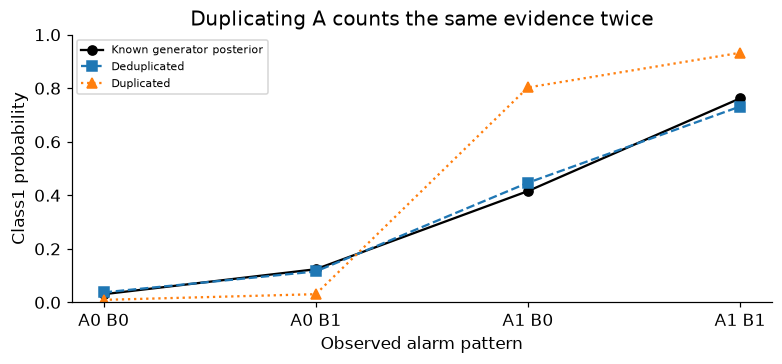

In [2]:
from scipy.special import logsumexp
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import brier_score_loss,log_loss,accuracy_score
def generate(n):
 y=rng.binomial(1,.2,n);a=rng.binomial(1,np.where(y==1,.8,.15));b=rng.binomial(1,np.where(y==1,.6,.25));return np.column_stack([a,b]),y
X,y=generate(600);Xt,yt=generate(3000);duplicate=lambda a:a[:,[0,0,1]];models={'Deduplicated':BernoulliNB(alpha=1,binarize=None).fit(X,y),'Duplicated':BernoulliNB(alpha=1,binarize=None).fit(duplicate(X),y)};features={'Deduplicated':Xt,'Duplicated':duplicate(Xt)};rows=[];probabilities={}
for name,model in models.items():
 a=features[name];theta=np.exp(model.feature_log_prob_);scores=model.class_log_prior_[None,:]+a@np.log(theta).T+(1-a)@np.log1p(-theta).T;manual=np.exp(scores-logsumexp(scores,axis=1,keepdims=True));np.testing.assert_allclose(manual,model.predict_proba(a),atol=1e-12);assert np.all((theta>0)&(theta<1));p=manual[:,1];probabilities[name]=p;rows.append({'model':name,'final_brier':float(brier_score_loss(yt,p)),'final_log_loss':float(log_loss(yt,p)),'final_accuracy_at_half':float(accuracy_score(yt,p>=.5))})
patterns=np.array([[0,0],[0,1],[1,0],[1,1]]);class_prior=np.array([.8,.2]);likelihood=np.ones((4,2))
for j,theta in enumerate([np.array([.15,.8]),np.array([.25,.6])]):likelihood*=theta[None,:]**patterns[:,j,None]*(1-theta[None,:])**(1-patterns[:,j,None])
posterior=likelihood*class_prior;posterior/=posterior.sum(axis=1,keepdims=True);assert np.allclose(posterior.sum(axis=1),1)
RESULTS['fits']=rows;RESULTS['pattern_probabilities']={'patterns_A_B':patterns.tolist(),'known_generator_class1_posterior':posterior[:,1].tolist(),'deduplicated_fitted':models['Deduplicated'].predict_proba(patterns)[:,1].tolist(),'duplicated_fitted':models['Duplicated'].predict_proba(duplicate(patterns))[:,1].tolist()};RESULTS['roles']={'train':600,'independent_final':3000,'fixed_smoothing_alpha':1,'selection':False}
fig,ax=plt.subplots(figsize=(7,3.2));x=np.arange(4);ax.plot(x,posterior[:,1],'-o',color='black',label='Known generator posterior')
for name,style in [('Deduplicated','--s'),('Duplicated',':^')]:ax.plot(x,RESULTS['pattern_probabilities'][name.lower()+'_fitted'],style,label=name)
ax.set(xticks=x,xticklabels=['A0 B0','A0 B1','A1 B0','A1 B1'],ylim=(0,1),xlabel='Observed alarm pattern',ylabel='Class1 probability',title='Duplicating A counts the same evidence twice');ax.legend(fontsize=7);plt.show()


<a id="calibration"></a>
## Normalize scores, then check their probability meaning

Bernoulli likelihood includes both presence and absence. Class log scores add prior log frequency plus each binary feature's log likelihood, then log-sum-exp normalizes across classes. The manual calculation agrees with the library. Calibration is inspected at the four distinct predicted scores per model using final empirical frequencies and counts. This reuses final outcomes for descriptive assessment, not tuning a correction. A small smoothing toy with absent indicators verifies finite probabilities; it does not justify multiplying duplicate reports.


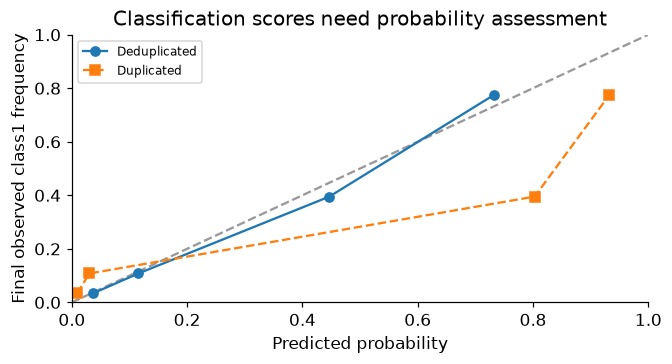

In [3]:
calibration=[];fig,ax=plt.subplots(figsize=(6,3.2));ax.plot([0,1],[0,1],'--',color='.6')
for name in models:
 p=probabilities[name];points=[]
 for value in np.unique(p):
  mask=p==value;points.append([float(value),float(yt[mask].mean()),int(mask.sum())])
 calibration.append({'model':name,'predicted_observed_count':points});ax.plot([v[0] for v in points],[v[1] for v in points],'--s' if name=='Duplicated' else '-o',label=name)
toy=BernoulliNB(alpha=1,binarize=None).fit(np.array([[0,0],[0,0],[1,0],[1,0]]),[0,0,1,1]);assert np.isfinite(toy.predict_log_proba([[0,1],[1,1]])).all()
RESULTS['calibration_by_distinct_score']=calibration;RESULTS['smoothing_toy_unobserved_feature_finite']=True;ax.set(xlim=(0,1),ylim=(0,1),xlabel='Predicted probability',ylabel='Final observed class1 frequency',title='Classification scores need probability assessment');ax.legend(fontsize=8);plt.show()


In [4]:
summary={'example_id':'code_077','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['Bernoulli class prior and likelihood score', 'Laplace smoothing and absent indicators', 'duplicate conditional dependence', 'classification versus probability calibration'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["Bernoulli class prior and likelihood score", "Laplace smoothing and absent indicators", "duplicate conditional dependence", "classification versus probability calibration"], "elapsed_seconds": 0.162, "example_id": "code_077", "hardware": "Darwin arm64 CPU", "results": {"calibration_by_distinct_score": [{"model": "Deduplicated", "predicted_observed_count": [[0.03721307712452384, 0.0341047503045067, 1642], [0.11538825030919683, 0.1079136690647482, 556], [0.4467214075013207, 0.3950892857142857, 448], [0.7315300018112155, 0.7740112994350282, 354]]}, {"model": "Duplicated", "predicted_observed_count": [[0.009243939369107753, 0.0341047503045067, 1642], [0.03052600690591308, 0.1079136690647482, 556], [0.802816364321768, 0.3950892857142857, 448], [0.9321577003507677, 0.7740112994350282, 354]]}], "fits": [{"final_accuracy_at_half": 0.8756666666666667, "final_brier": 0.09282850147029599, "final_log_loss": 0.3095730316148787, "model": "Deduplicat